# Breast Cancer Survival Analysis (GBSG Dataset)

Recurrence-free survival analysis of 686 breast cancer patients from the German Breast Cancer Study Group (GBSG) trial, using:

1. **Kaplan–Meier** curves and **log-rank** tests
2. **Cox Proportional Hazards** regression
3. **Gradient Boosting Survival Analysis** (scikit-survival)

**Dataset:** [Breast Cancer Dataset (Royston & Altman)](https://www.kaggle.com/datasets/utkarshx27/breast-cancer-dataset-used-royston-and-altman) on Kaggle.

## 1. Setup

In [2]:
# Install dependencies first:  pip install -r requirements.txt
# (in Google Colab run:  !pip install -q lifelines scikit-survival)

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

from sksurv.ensemble import GradientBoostingSurvivalAnalysis
from sksurv.metrics import concordance_index_censored
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load data

The notebook first looks for a local copy at `data/gbsg.csv`. If it is not found, the dataset is downloaded from Kaggle with `kagglehub` (requires internet).

In [3]:
LOCAL_PATH = Path("../data/gbsg.csv")

if LOCAL_PATH.exists():
    csv_path = LOCAL_PATH
else:
    import kagglehub
    folder = kagglehub.dataset_download("utkarshx27/breast-cancer-dataset-used-royston-and-altman")
    csv_path = Path(folder) / "gbsg.csv"

df = pd.read_csv(csv_path)
df = df.drop(columns=["Unnamed: 0"], errors="ignore")   # stray index column, if present
print(df.shape)
df.head()

100%|██████████| 9.86k/9.86k [00:00<00:00, 7.29MB/s]

Extracting files...
(686, 11)


,pid,age,meno,size,grade,nodes,pgr,er,hormon,rfstime,status
0,132,49,0,18,2,2,0,0,0,1838,0
1,1575,55,1,20,3,16,0,0,0,403,1
2,1140,56,1,40,3,3,0,0,0,1603,0
3,769,45,0,25,3,1,0,4,0,177,0
4,130,65,1,30,2,5,0,36,1,1855,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 686 entries, 0 to 685
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   pid      686 non-null    int64
 1   age      686 non-null    int64
 2   meno     686 non-null    int64
 3   size     686 non-null    int64
 4   grade    686 non-null    int64
 5   nodes    686 non-null    int64
 6   pgr      686 non-null    int64
 7   er       686 non-null    int64
 8   hormon   686 non-null    int64
 9   rfstime  686 non-null    int64
 10  status   686 non-null    int64
dtypes: int64(11)
memory usage: 59.1 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pid,686.0,966.061224,495.506249,1.0,580.75,1015.5,1340.50,1819.0
age,686.0,53.052478,10.120739,21.0,46.00,53.0,61.00,80.0
meno,686.0,0.577259,0.494355,0.0,0.00,1.0,1.00,1.0
size,686.0,29.329446,14.296217,3.0,20.00,25.0,35.00,120.0
grade,686.0,2.116618,0.582808,1.0,2.00,2.0,2.00,3.0
nodes,686.0,5.010204,5.475483,1.0,1.00,3.0,7.00,51.0
pgr,686.0,109.995627,202.331552,0.0,7.00,32.5,131.75,2380.0
er,686.0,96.252187,153.083963,0.0,8.00,36.0,114.00,1144.0
hormon,686.0,0.358601,0.479940,0.0,0.00,0.0,1.00,1.0
rfstime,686.0,1124.489796,642.791948,8.0,567.75,1084.0,1684.75,2659.0


### Data dictionary

| Column | Description |
| ------ | ----------- |
| `pid` | Patient identifier |
| `age` | Age (years) |
| `meno` | Menopausal status (0 = pre, 1 = post) |
| `size` | Tumour size (mm) |
| `grade` | Tumour grade |
| `nodes` | Number of positive lymph nodes |
| `pgr` | Progesterone receptors (fmol/L) |
| `er` | Estrogen receptors (fmol/L) |
| `hormon` | Hormonal therapy (0 = no, 1 = yes) |
| `rfstime` | Recurrence-free survival time (days) |
| `status` | Event indicator (0 = censored, 1 = recurrence or death) |

In [6]:
print("Missing values:", int(df.isna().sum().sum()))
print("Events (status=1):", int(df["status"].sum()), "| Censored:", int((df["status"] == 0).sum()))

Missing values: 0
Events (status=1): 299 | Censored: 387


## 3. Kaplan–Meier survival analysis

### 3.1 Overall curve

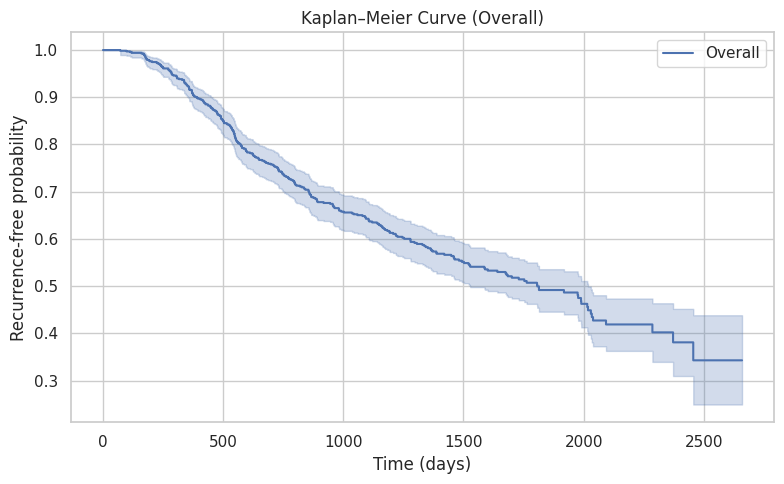

Median recurrence-free time (days): 1807.0


In [7]:
kmf = KaplanMeierFitter()
kmf.fit(durations=df["rfstime"], event_observed=df["status"], label="Overall")

fig, ax = plt.subplots(figsize=(8, 5))
kmf.plot_survival_function(ax=ax)
ax.set_xlabel("Time (days)")
ax.set_ylabel("Recurrence-free probability")
ax.set_title("Kaplan–Meier Curve (Overall)")
plt.tight_layout()
plt.show()

print("Median recurrence-free time (days):", kmf.median_survival_time_)

In [8]:
kmf.survival_function_.head()

,Overall
timeline,
0.0,1.0
8.0,1.0
15.0,1.0
16.0,1.0
17.0,1.0


In [9]:
kmf.confidence_interval_.tail()

,Overall_lower_0.95,Overall_upper_0.95
2551.0,0.249125,0.438274
2556.0,0.249125,0.438274
2563.0,0.249125,0.438274
2612.0,0.249125,0.438274
2659.0,0.249125,0.438274


### 3.2 Helper to compare groups

In [10]:
def plot_km_by_group(data, column, labels=None, title=None, ax=None):
    """Fit and plot one KM curve per unique value of `column`."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5.5))
    for value in sorted(data[column].unique()):
        mask = data[column] == value
        name = labels.get(value, value) if labels else value
        KaplanMeierFitter().fit(
            data.loc[mask, "rfstime"],
            data.loc[mask, "status"],
            label=f"{column} = {name} (n={mask.sum()})",
        ).plot_survival_function(ax=ax)
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Recurrence-free probability")
    ax.set_title(title or f"Kaplan–Meier Curve by {column}")
    ax.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    return ax

### 3.3 By hormonal therapy (with log-rank test)

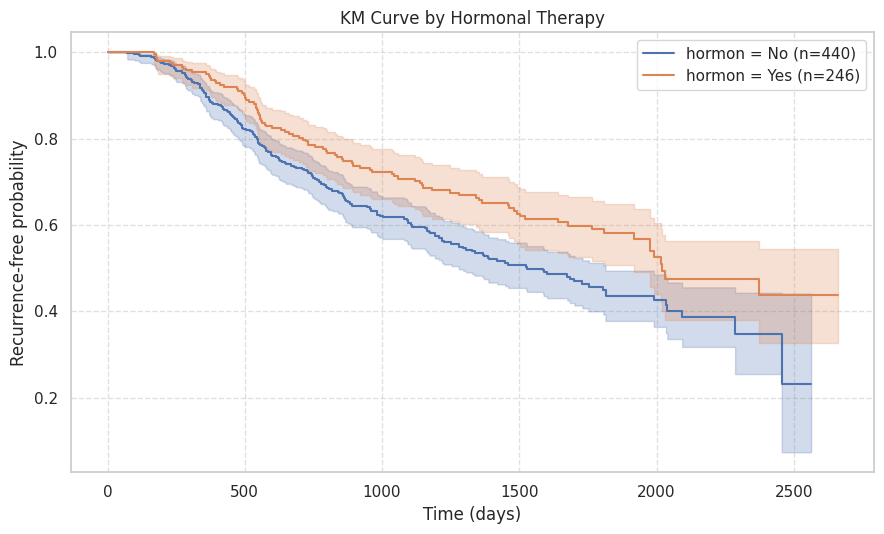

In [11]:
plot_km_by_group(df, "hormon", labels={0: "No", 1: "Yes"}, title="KM Curve by Hormonal Therapy")
plt.show()

In [12]:
g0, g1 = df[df["hormon"] == 0], df[df["hormon"] == 1]

lr = logrank_test(
    g0["rfstime"], g1["rfstime"],
    event_observed_A=g0["status"], event_observed_B=g1["status"],
)
lr.print_summary()

### 3.4 By menopausal status

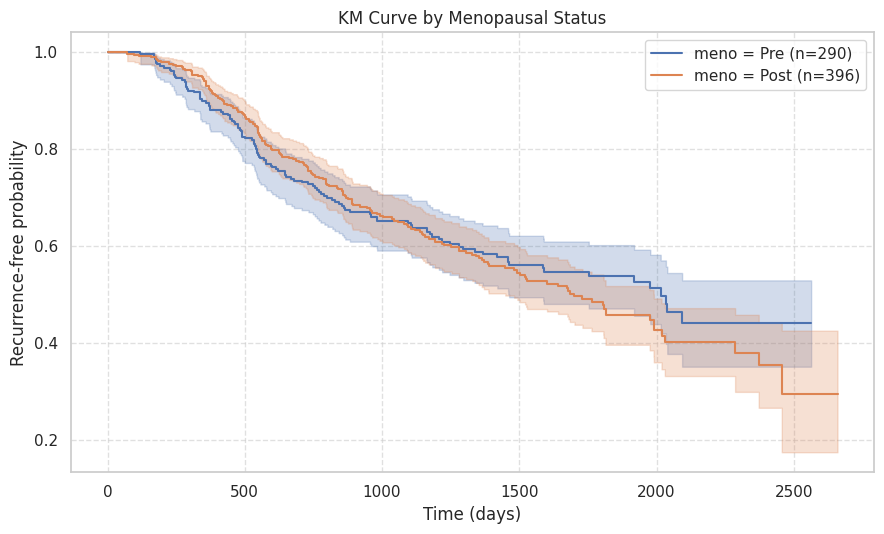

In [13]:
plot_km_by_group(df, "meno", labels={0: "Pre", 1: "Post"}, title="KM Curve by Menopausal Status")
plt.show()

### 3.5 By tumour grade

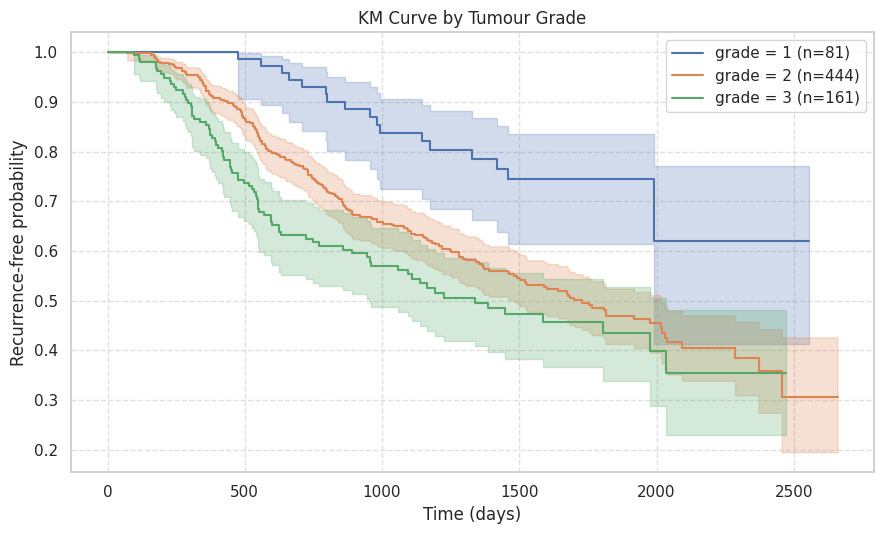

In [14]:
plot_km_by_group(df, "grade", title="KM Curve by Tumour Grade")
plt.show()

### 3.6 By age and lymph-node thresholds

> **Note:** these groups are *cumulative* (e.g. `age > 25` contains everyone in `age > 40`), so the curves overlap by design. They show how survival changes as the threshold rises, not independent groups.

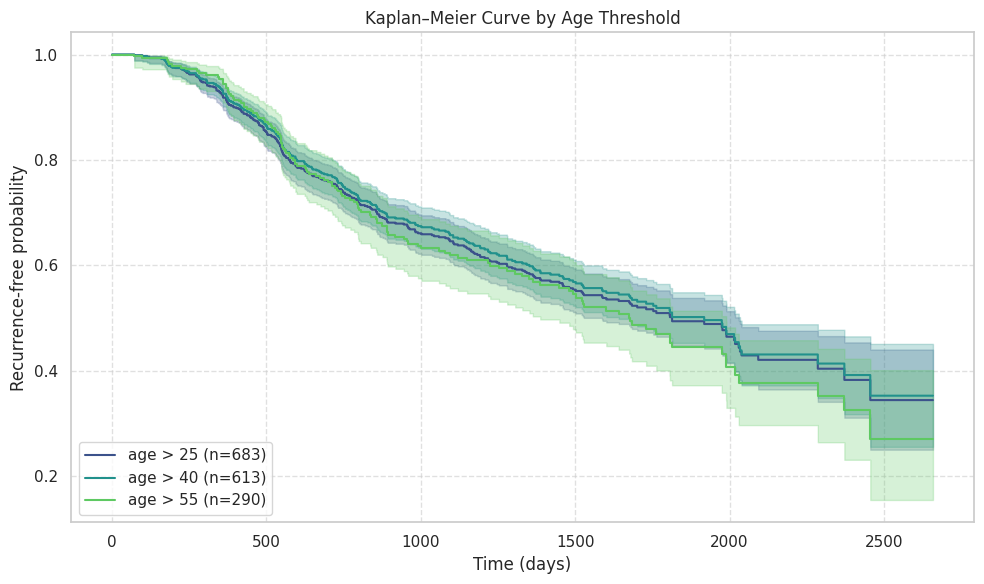

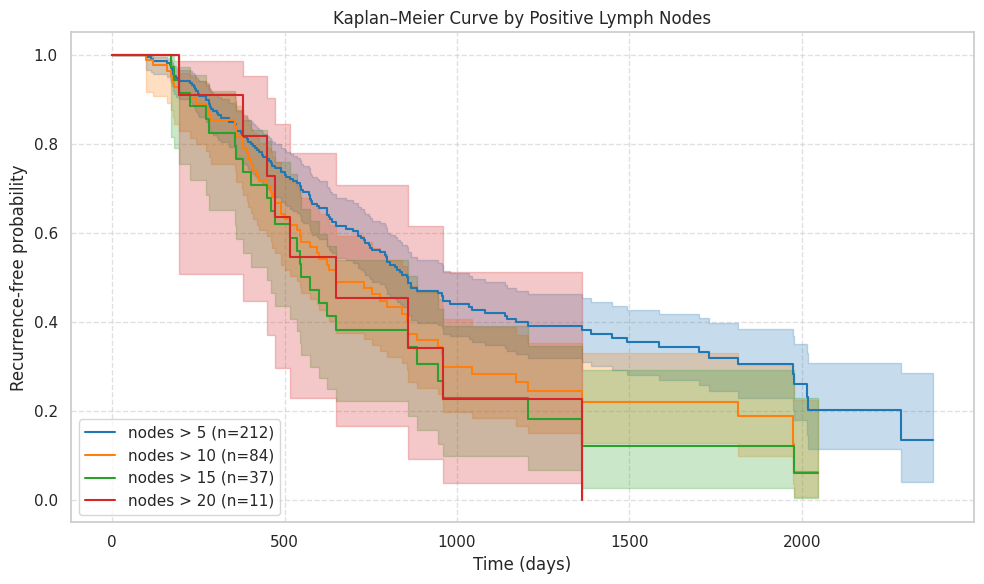

In [15]:
def plot_km_thresholds(data, column, thresholds, title, palette="viridis"):
    colors = sns.color_palette(palette, n_colors=len(thresholds))
    _, ax = plt.subplots(figsize=(10, 6))
    for color, t in zip(colors, thresholds):
        sub = data[data[column] > t]
        KaplanMeierFitter().fit(
            sub["rfstime"], sub["status"], label=f"{column} > {t} (n={len(sub)})"
        ).plot_survival_function(ax=ax, color=color)
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Recurrence-free probability")
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(loc="lower left")
    plt.tight_layout()
    plt.show()

plot_km_thresholds(df, "age", [25, 40, 55], "Kaplan–Meier Curve by Age Threshold")
plot_km_thresholds(df, "nodes", [5, 10, 15, 20], "Kaplan–Meier Curve by Positive Lymph Nodes", palette="tab10")

## 4. Cox Proportional Hazards model

Fits all covariates (except `pid`) simultaneously. A hazard ratio (`exp(coef)`) above 1 means higher risk of recurrence/death.

In [16]:
df_model = df.drop(columns=["pid"])

cph = CoxPHFitter()
cph.fit(df_model, duration_col="rfstime", event_col="status")
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 686 total observations, 387 right-censored observations>
             duration col = 'rfstime'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 686
number of events observed = 299
   partial log-likelihood = -1737.17
         time fit was run = 2026-10-03 16:16:25 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
age       -0.01      0.99      0.01           -0.03            0.01                0.97                1.01
meno       0.27      1.31      0.18           -0.09            0.63                0.91                1.87
size       0.01      1.01      0.00           -0.00            0.02                1.00                1.02
grade      0.28      1.32      0.11            0.07            0.49                1.08                1.63
nodes      0.05      1.05      0.01            0.04            0.06                1.04                1.07
pgr       -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
er         0.00      1.00      0.00           -0.00            0.00                1.00                1.00
hormon    -0.34      0.71      0.13           -0.59           -0.08                0.55                0.92

           cmp to     z      p  -log2(p)
covariate                               
age          0.00 -1.01   0.31      1.68
meno         0.00  1.46   0.14      2.79
size         0.00  1.95   0.05      4.30
grade        0.00  2.64   0.01      6.93
nodes        0.00  6.73 <0.005     35.82
pgr          0.00 -3.89 <0.005     13.26
er           0.00  0.37   0.71      0.50
hormon       0.00 -2.61   0.01      6.81
---
Concordance = 0.69
Partial AIC = 3490.35
log-likelihood ratio test = 101.86 on 8 df
-log2(p) of ll-ratio test = 58.96

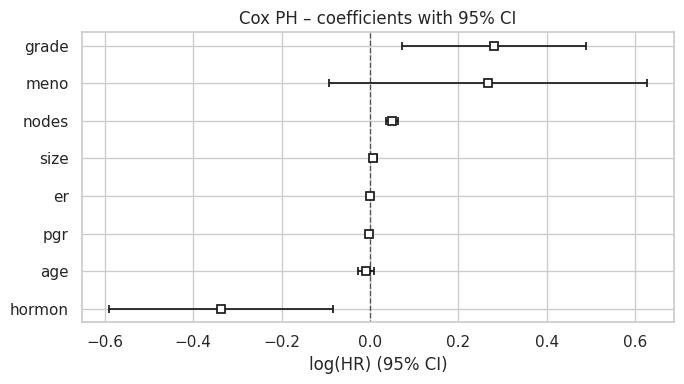

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
cph.plot(ax=ax)
ax.set_title("Cox PH – coefficients with 95% CI")
plt.tight_layout()
plt.show()

## 5. Survival Gradient Boosting

Gradient boosting for right-censored data. It captures non-linear effects and interactions without the proportional-hazards assumption.

In [18]:
X = df_model.drop(columns=["rfstime", "status"])
y = np.array(
    list(zip(df_model["status"].astype(bool), df_model["rfstime"].astype(float))),
    dtype=[("event", "?"), ("time", "<f8")],
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (548, 8) | Test: (138, 8)


In [19]:
sgb = GradientBoostingSurvivalAnalysis(
    n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE
)
sgb.fit(X_train, y_train)

risk_scores = sgb.predict(X_test)
c_index = concordance_index_censored(y_test["event"], y_test["time"], risk_scores)[0]
print(f"Test C-index: {c_index:.3f}")

Test C-index: 0.655


,Feature,Importance
0,nodes,2.944337e-01
1,pgr,2.122874e-01
2,age,1.883917e-01
3,size,1.402766e-01
4,er,1.104675e-01
5,hormon,2.756991e-02
6,grade,2.657243e-02
7,meno,6.818678e-07


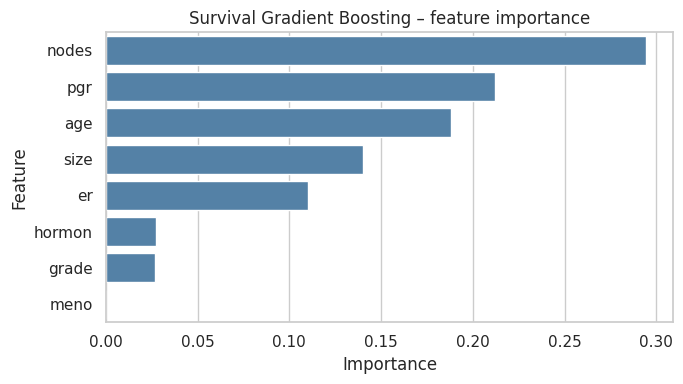

In [20]:
importance = (
    pd.DataFrame({"Feature": X.columns, "Importance": sgb.feature_importances_})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
display(importance)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=importance, x="Importance", y="Feature", color="steelblue", ax=ax)
ax.set_title("Survival Gradient Boosting – feature importance")
plt.tight_layout()
plt.show()

### Predicted survival curves for individual patients

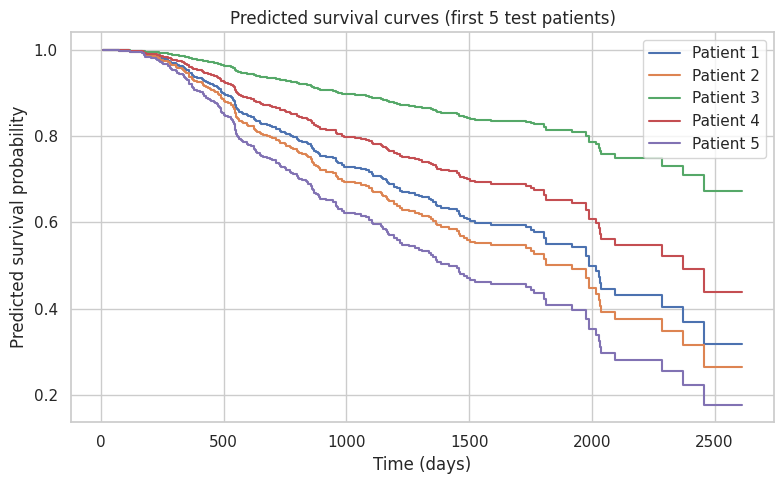

In [21]:
surv_funcs = sgb.predict_survival_function(X_test)

fig, ax = plt.subplots(figsize=(8, 5))
for i, fn in enumerate(surv_funcs[:5]):
    ax.step(fn.x, fn.y, where="post", label=f"Patient {i + 1}")
ax.set_xlabel("Time (days)")
ax.set_ylabel("Predicted survival probability")
ax.set_title("Predicted survival curves (first 5 test patients)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Model comparison

In [22]:
# Cox concordance on the same held-out split, for a like-for-like comparison
train_idx, test_idx = X_train.index, X_test.index
cph_split = CoxPHFitter().fit(df_model.loc[train_idx], duration_col="rfstime", event_col="status")
cox_risk = cph_split.predict_partial_hazard(df_model.loc[test_idx])
cox_c = concordance_index_censored(y_test["event"], y_test["time"], cox_risk.values)[0]

print(pd.DataFrame({
    "Model": ["Cox PH", "Survival Gradient Boosting"],
    "Test C-index": [round(cox_c, 3), round(c_index, 3)],
}).to_string(index=False))

                     Model  Test C-index
                    Cox PH         0.663
Survival Gradient Boosting         0.655


## 7. Conclusions

- Positive lymph nodes is the strongest predictor of recurrence/death in both the Cox model and the boosting model.
- Hormonal therapy is associated with a lower hazard of recurrence/death (log-rank test p < 0.005; Cox HR = 0.71).
- Higher tumour grade is associated with higher risk; progesterone receptor level is also significant in the Cox model.
- On the same 80/20 split, the simple Cox model (test C-index 0.663) performed slightly better than Survival Gradient Boosting (0.655). With only 686 patients and 299 events, the added flexibility of boosting did not pay off here.
- Both C-indices are modest and come from a single split, so cross-validation is needed before drawing conclusions about which model is better.

*This is an educational analysis of a public dataset, not medical advice.*